<a href="https://colab.research.google.com/github/kamilaarriagadaq/sic_ia_2026/blob/main/clase03_grupo2A_Albarran_Arriagada_Perez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Supervisado



## Tipos de Error: Sesgo, Varianza y Error Total

El **Error de Prueba** (test error o error de generalización) es una métrica clave para evaluar un modelo en Machine Learning. Mide qué tan bien predice el modelo sobre datos totalmente nuevos que nunca vio durante su entrenamiento.
A diferencia del error de entrenamiento, que mide memorización, el error de prueba evalúa si el modelo aprendio el patrón verdadero del fenómeno.

$$\text{Error Total} = \text{Sesgo}^2 + \text{Varianza} + \text{Error Irreducible } (\sigma^2)$$

<br>

*   **Sesgo (subajuste):** Es el error introducido al simplificar un problema complejo mediante un modelo demasiado sencillo, por ejemplo: intentar ajustar una relación no lineal usando una recta. El modelo no logra capturar la estructura subyacente de los datos, dando un rendimiento pobre tanto en entrenamiento como en prueba.

*   **Varianza (sobreajuste):** Es la sensibilidad del modelo a pequeñas fluctuaciones en el conjunto de entrenamiento. Ocurre cuando el modelo memoriza el ruido y las particularidades de los datos de entrenamiento en lugar de aprender el patrón general. Tiene un error muy bajo en entrenamiento, pero un error alto en pruebas.

*   **Error Irreductible ($\sigma^2$):** Es el ruido inherente a los datos o varibales no observadas. No se puede eliminar independiente del modelo elegido.

<br>

**¿Cómo se llega al Error de Prueba Mínimo?**

El error de prueba total forma una curva en forma de "U" al aumentar la complejidad del modelo:

* Al principio, **incrementar la complejidad disminuye drásticamente el sesgo**, reduciendo el error total.

* Sin embargo, sobrepasar cierto umbral provoca que la varianza crezca a un ritmo mayor de lo que disminuye el sesgo.

**El punto óptimo** ocurre exactamente en la parte **más baja de la curva** "U", donde se alcanza la combinación ideal que minimiza la suma de $\text{Sesgo}^2 + \text{Varianza}$.


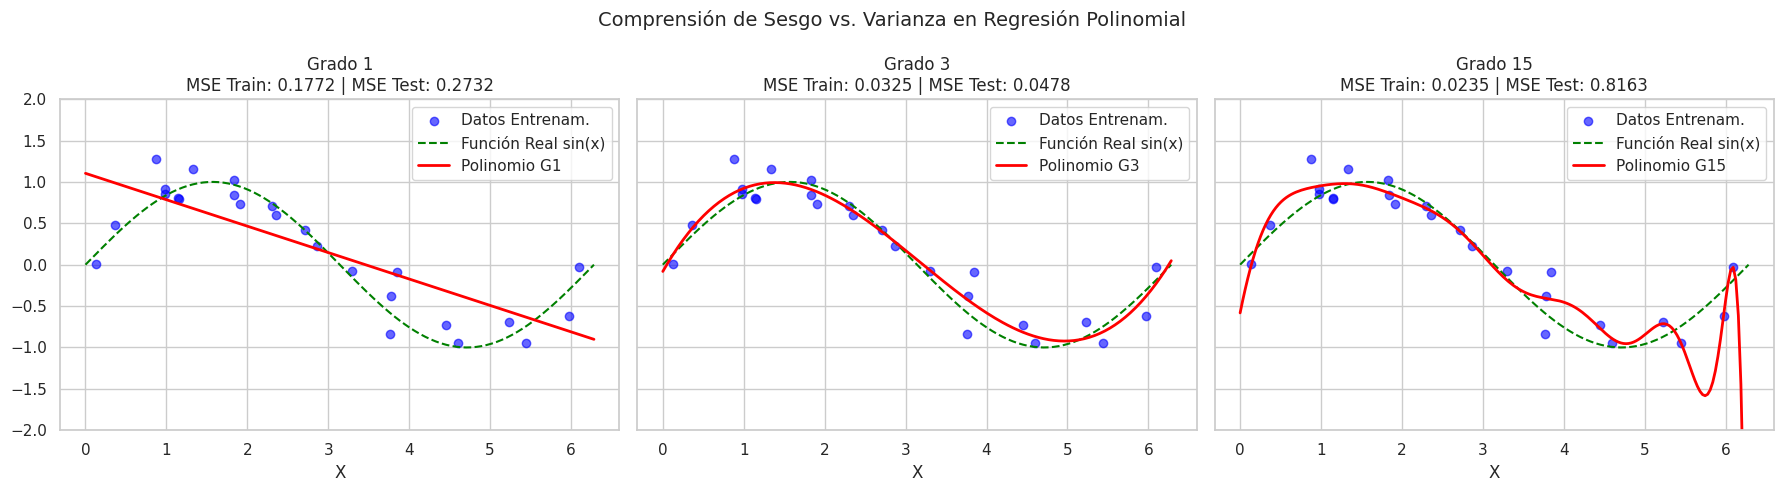

 Grado del Polinomio  MSE Entrenamiento  MSE Prueba
                   1             0.1772      0.2732
                   3             0.0325      0.0478
                  15             0.0235      0.8163


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Fijar semilla para reproducibilidad
np.random.seed(42)

# 1. Definir función verdadera f(x) = sin(x)
def f(x):
    return np.sin(x)

# 2. Generar datos de Entrenamiento (25 puntos con ruido)
X_train = np.sort(np.random.uniform(0, 2 * np.pi, 25)).reshape(-1, 1)
y_train = f(X_train).ravel() + np.random.normal(0, 0.2, 25)

# 3. Generar datos de Prueba (100 puntos con ruido)
X_test = np.linspace(0, 2 * np.pi, 100).reshape(-1, 1)
y_test = f(X_test).ravel() + np.random.normal(0, 0.2, 100)

grados = [1, 3, 15]
resultados = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
X_plot = np.linspace(0, 2 * np.pi, 200).reshape(-1, 1)

for ax, g in zip(axes, grados):
    # Crear y entrenar pipeline
    modelo = make_pipeline(PolynomialFeatures(degree=g), LinearRegression())
    modelo.fit(X_train, y_train)

    # Evaluar en entrenamiento y prueba
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    mse_train = mean_squared_error(y_train, pred_train)
    mse_test = mean_squared_error(y_test, pred_test)

    resultados.append({
        'Grado del Polinomio': g,
        'MSE Entrenamiento': round(mse_train, 4),
        'MSE Prueba': round(mse_test, 4)
    })

    # Graficar
    ax.scatter(X_train, y_train, color='blue', alpha=0.6, label='Datos Entrenam.')
    ax.plot(X_plot, f(X_plot), color='green', linestyle='--', label='Función Real sin(x)')
    ax.plot(X_plot, modelo.predict(X_plot), color='red', linewidth=2, label=f'Polinomio G{g}')
    ax.set_title(f'Grado {g}\nMSE Train: {mse_train:.4f} | MSE Test: {mse_test:.4f}')
    ax.set_xlabel('X')
    ax.set_ylim(-2, 2)
    ax.legend()

plt.suptitle('Comprensión de Sesgo vs. Varianza en Regresión Polinomial', fontsize=14)
plt.tight_layout()
plt.show()

# Imprimir tabla de métricas
print(pd.DataFrame(resultados).to_string(index=False))

## Regresión Lineal

Es un método supervisado para modelar la relación cuantitativa entre una variable respuesta ($Y$) y una o más variables explicativas ($X$), ajustando una función lineal que minimiza la distancia entre los datos reales y la predicción.

<br>

El fundamento matemático de la regresión lineal nació a inicios del siglo XIX gracias al método de Mínimos Cuadrados. **Legendre (1805)** fue el primero en publicar formalmente el método para resolver sistemas de ecuaciones lineales incosistentes en la determinación de órbitas astronómica. Y en **1809, Gauss** afirmó haber usado el método desde 1795 para predecir la ubicación del asteroide Ceres.

<br>

Sir Francis Galton en 1886 estudió la relación entre la altura de los padres y la de sus hijos adultos. Y notó que aunque los padres altos tienden a tener hijos altos, la altura promedio de estos hijos es más cercana a la media poblacional que a la de sus padres. Denominó a este fenómeno "**regresión hacia la mediocridad**", lo que dio origen al término regresión.

Posteriormente, Karl Pearson y el estadístico Gorge Udny Yule formalizaron el marco matemático moderno para variables continuas, conservando la palabra regresión para nombrar el análisis de ajuste lineal.


<br>

**Regresión Lineal Simple**

$$Y = \beta_0 + \beta_1 X + \epsilon$$

Donde:

$Y$: Variable dependiente predicha.

$X$: Variable independiente.

$\beta_0$: Intersección con el eje Y (el valor de $Y$ cuando $X = 0$).

$\beta_1$: Pendiente de la recta (cuánto cambia $Y$ por cada unidad que aumenta $X$).

$\epsilon$: Variabilidad no explicada por el modelo debido al azar o factores no observados. (diferencia entre el valor real y la predicción).

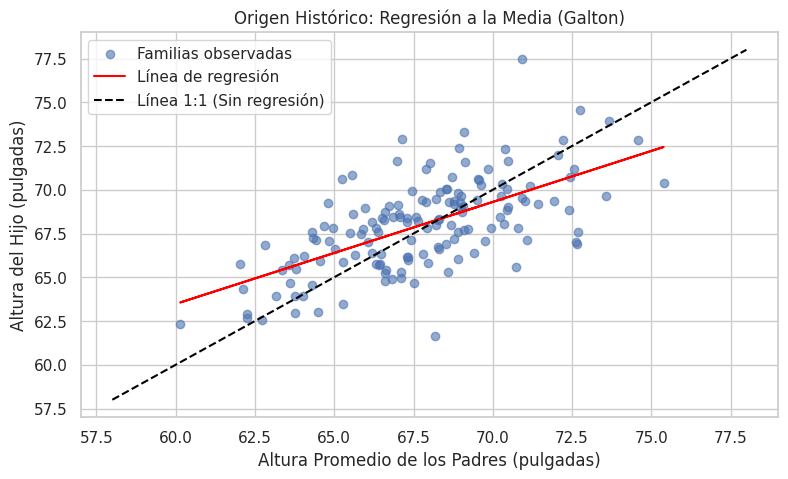

Galton - Pendiente: 0.58


In [ ]:
import seaborn as sns

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# ==============================================================================
# ORIGEN DE LA REGRESIÓN: EL EXPERIMENTO DE GALTON
# ==============================================================================
np.random.seed(42)  # Semilla para hacer el experimento reproducible

# Simulamos la altura de los padres e hijos (en pulgadas)
altura_padres = np.random.normal(loc=68, scale=3, size=150)
# La pendiente es 0.6 (< 1), lo que demuestra la "regresión a la media"
altura_hijos = 0.6 * altura_padres + 27.2 + np.random.normal(0, 2, 150)

datos_galton = pd.DataFrame({'padre': altura_padres, 'hijo': altura_hijos})

# Modelo de regresión lineal para Galton
modelo_galton = LinearRegression().fit(datos_galton[['padre']], datos_galton['hijo'])

plt.figure()
plt.scatter(datos_galton['padre'], datos_galton['hijo'], alpha=0.6, label="Familias observadas")
plt.plot(datos_galton['padre'], modelo_galton.predict(datos_galton[['padre']]),
         color="red", label="Línea de regresión")
plt.plot([58, 78], [58, 78], color="black", linestyle="--", label="Línea 1:1 (Sin regresión)")
plt.xlabel("Altura Promedio de los Padres (pulgadas)")
plt.ylabel("Altura del Hijo (pulgadas)")
plt.title("Origen Histórico: Regresión a la Media (Galton)")
plt.legend()
plt.show()

print(f"Galton - Pendiente: {modelo_galton.coef_[0]:.2f}")

## Mínimos Cuadrados Ordinarios (OLS)

Su objetivo principal es encontrar la "línea de mejor ajuste" que atraviesa un conjunto de puntos de datos.

<br>

**¿Cómo funciona OLS?**
1.   **Calcula el residuo o error:** Para cada punto de datos observados ($y_i$), OLS mide la distancia vertical entre ese punto real y el valor que predice la recta ($\hat{y}_i$). Esta diferencia se llama residuo.
$$e_i = y_i - \hat{y}_i = y_i - (\beta_0 + \beta_1 x_i)$$

<br>

2.   **Eleva los errores al cuadrado:** Eleva cada residuo al cuadrado ($e_i^2$). Esto cumple 2 propositos fundamentales:

*   Evita que los errores positivos y negativos se cancelen entre sí.
*   Penaliza con mayor severidad a las desviaciones o errores más grandes.

3. **Minimiza la suma total:** OLS busca la pendiente ($\beta_1$) y el intercepto ($\beta_0$) que logren la menor Suma de los Residuos al Cuadrado (RSS).

$$\text{RSS} = \sum_{i=1}^{n} e_i^2 = \sum_{i=1}^{n} (y_i - (\beta_0 + \beta_1 x_i))^2$$



## Métricas de Error en Profundidad
Para saber qué tan bueno es un modelo en la fase de predicción, se comparan los valores reales ($y$) con las predicciones ($\hat{y}$) mediante métricas cuantitativas.

*   **Error Cuadrático Medio (MSE):**  Es el promedio directo de todos los errores elevados al cuadrado. Su desventaja es que las unidades quedan al cuadrado, lo cual no tiene una interpretación práctica.

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

<br>

*   **Raíz del Error Cuadrático Medio (RMSE):** Aplica la raíz cuadrada a MSE para devolver el error a las mismas unidades originales de la variable original ($y$). Es muy sensible a errores atípicos muy grandes.

$$\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

<br>

*   **Error Absoluto Medio (MAE):** Mide el promedio de las magnitudes de los errores en términos absolutos, ignorando la dirección, si fue por exceso o por defecto. Trata a todos los errores por igual de forma lineal. Es altamente robusto frente a datos atípicos o ruidosos.

$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}$$


In [ ]:
# ==============================================================================
# MODELO BASE CON 'MPG' Y CÁLCULO OLS A MANO
# ==============================================================================
# Cargar datos de autos y renombrar columnas al español para mayor claridad
autos = sns.load_dataset("mpg").dropna()
autos = autos.rename(columns={'weight': 'peso', 'mpg': 'rendimiento', 'origin': 'origen'})

X_peso = autos[["peso"]]
y_rendimiento = autos["rendimiento"]

# A) Modelo ajustado con scikit-learn
modelo_base = LinearRegression().fit(X_peso, y_rendimiento)

print(f"\n--- Modelo Base (Rendimiento según Peso) ---")
print(f"Intercepto (beta_0): {modelo_base.intercept_:.2f}")
print(f"Pendiente (beta_1): {modelo_base.coef_[0]:.4f}")
print(f"Por cada 1000 libras adicionales, el rendimiento cambia en: {modelo_base.coef_[0] * 1000:.2f} mpg")

# B) Cálculo de Mínimos Cuadrados Ordinarios (OLS) mediante álgebra lineal
# Formula: beta = (X^T * X)^(-1) * X^T * y
matriz_X = np.column_stack([np.ones(len(X_peso)), X_peso])  # Matriz con columna de unos
beta_manual = np.linalg.inv(matriz_X.T @ matriz_X) @ matriz_X.T @ y_rendimiento
print("OLS manual con álgebra lineal (beta_0, beta_1):", beta_manual.round(4))

# C) Evaluación con métricas de error
predicciones_base = modelo_base.predict(X_peso)
rmse = mean_squared_error(y_rendimiento, predicciones_base) ** 0.5
mae = mean_absolute_error(y_rendimiento, predicciones_base)
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.2f} mpg")
print(f"MAE (Error Absoluto Medio): {mae:.2f} mpg")


--- Modelo Base (Rendimiento según Peso) ---
Intercepto (beta_0): 46.22
Pendiente (beta_1): -0.0076
Por cada 1000 libras adicionales, el rendimiento cambia en: -7.65 mpg
OLS manual con álgebra lineal (beta_0, beta_1): [ 4.62165e+01 -7.60000e-03]
RMSE (Raíz del Error Cuadrático Medio): 4.32 mpg
MAE (Error Absoluto Medio): 3.28 mpg


In [ ]:

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline



## Variables Categóricas (o Cualitativas) en Regresión

Representan atributos no numéricos como el tipo de combustible, origen de un producto o el género. Dado que los  algoritmos de regresión lineal trabajan exclusivamente con operaciones matemáticas, estas variables deben codificarse numéricamente antes de incorporarse al modelo.

* **Variables Dummies (Indicadoras):** Es una variable binaria, que toma el valor $1$ para indicar la presencia de un nivel de categoría y $0$ para su ausencia. Si una variable categoríca tiene $K$ niveles o categorías, se deben incluir solo $K - 1$ variables dummy en el modelo.

Modelo con dummy $D \in \{0, 1\}$: $y = \beta_0 + \beta_1 X + \beta_2 D + \epsilon$

* **Términos de Interacción:** A menudo, la tasa de cambio de la respuesta $y$ con respecto a $x$ no es la misma en todos los subgrupos. Para permitir que la inclinación varíe según la categoría, agregamos un término de interacción (el producto cruzado $x * D_1$)

$$y = \beta_0 + \beta_1 x + \beta_2 D_1 + \beta_3 (x \cdot D_1) + \epsilon$$



--- Modelo con Variable Dummy ---
Intercepto Base (Vehículos No USA): 45.57
Efecto Dummy USA (beta_2 - desplaza el intercepto): -1.64 mpg
Pendiente del Peso (compartida por ambos grupos): -0.0071

--- Modelo con Término de Interacción ---
Pendiente del Peso en autos No-USA: -0.0085
Pendiente del Peso en autos USA (beta_1 + beta_3): -0.0069


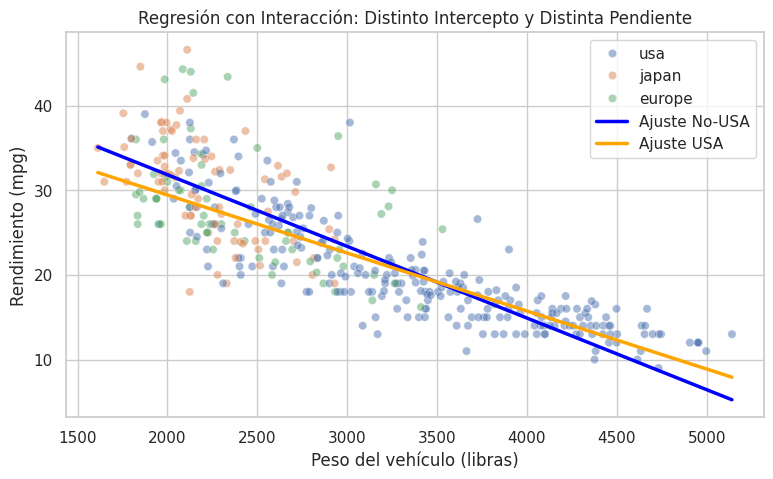

In [ ]:
# ==============================================================================
# VARIABLES CATEGÓRICAS: DUMMIES E INTERACCIÓN
# ==============================================================================

# Crear variable dummy binaria (1 si es USA, 0 si es otro país)
autos['es_usa'] = (autos['origen'] == 'usa').astype(int)

# ------------------------------------------------------------------------------
# Caso A: Modelo con Variable Dummy (Afecta el Intercepto)
# Ecuación: rendimiento = beta_0 + beta_1 * peso + beta_2 * es_usa
# ------------------------------------------------------------------------------
X_dummy = autos[['peso', 'es_usa']]
modelo_dummy = LinearRegression().fit(X_dummy, y_rendimiento)

print(f"\n--- Modelo con Variable Dummy ---")
print(f"Intercepto Base (Vehículos No USA): {modelo_dummy.intercept_:.2f}")
print(f"Efecto Dummy USA (beta_2 - desplaza el intercepto): {modelo_dummy.coef_[1]:.2f} mpg")
print(f"Pendiente del Peso (compartida por ambos grupos): {modelo_dummy.coef_[0]:.4f}")

# ------------------------------------------------------------------------------
# Caso B: Modelo con Interacción (Afecta Intercepto y Pendiente)
# Ecuación: rendimiento = beta_0 + beta_1 * peso + beta_2 * es_usa + beta_3 * (peso * es_usa)
# ------------------------------------------------------------------------------
autos['peso_x_usa'] = autos['peso'] * autos['es_usa']

X_interaccion = autos[['peso', 'es_usa', 'peso_x_usa']]
modelo_interaccion = LinearRegression().fit(X_interaccion, y_rendimiento)

print(f"\n--- Modelo con Término de Interacción ---")
print(f"Pendiente del Peso en autos No-USA: {modelo_interaccion.coef_[0]:.4f}")
print(f"Pendiente del Peso en autos USA (beta_1 + beta_3): {modelo_interaccion.coef_[0] + modelo_interaccion.coef_[2]:.4f}")

# Gráfico del modelo con interacción
plt.figure()
sns.scatterplot(data=autos, x="peso", y="rendimiento", hue="origen", alpha=0.5)

rango_peso = np.linspace(autos["peso"].min(), autos["peso"].max(), 100)

df_pred_no_usa = pd.DataFrame({'peso': rango_peso, 'es_usa': 0, 'peso_x_usa': 0})
df_pred_usa = pd.DataFrame({'peso': rango_peso, 'es_usa': 1, 'peso_x_usa': rango_peso})

pred_no_usa = modelo_interaccion.predict(df_pred_no_usa)
pred_usa = modelo_interaccion.predict(df_pred_usa)

plt.plot(rango_peso, pred_no_usa, color="blue", linewidth=2.5, label="Ajuste No-USA")
plt.plot(rango_peso, pred_usa, color="orange", linewidth=2.5, label="Ajuste USA")
plt.title("Regresión con Interacción: Distinto Intercepto y Distinta Pendiente")
plt.xlabel("Peso del vehículo (libras)")
plt.ylabel("Rendimiento (mpg)")
plt.legend()
plt.show()